<a href="https://colab.research.google.com/github/wildemar66/Project_Analisis_churn/blob/main/notebooks/Analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
from google.colab import drive
drive.mount('/content/drive')

# jalur folder
BASE_PATH = '/content/drive/MyDrive/Project_Analisis_churn'
REPORTS = f'{BASE_PATH}/Reports'

# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load Data

In [39]:
df = pd.read_csv(f'{BASE_PATH}/Data/Processed/data_bersih.csv')
df.sample(5)

,Unnamed: 0,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
1169,1169,3018-TFTSU,1,United States,California,Hathaway Pines,95233,"38.184914, -120.364085",38.184914,-120.364085,Male,No,No,No,12,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,No,Bank transfer (automatic),81.70,858.60,Yes,1,76,2850,Poor expertise of phone support
6545,6545,1936-UAFEH,1,United States,California,Pioneer,95666,"38.546999, -120.271114",38.546999,-120.271114,Female,No,No,No,68,Yes,Yes,Fiber optic,Yes,Yes,No,Yes,Yes,Yes,Two year,No,Credit card (automatic),110.25,7279.35,No,0,36,5502,NaN
3456,3456,9297-FVVDH,1,United States,California,Hemet,92545,"33.734933, -117.044145",33.734933,-117.044145,Female,No,Yes,No,57,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,84.50,4845.40,No,0,41,5928,NaN
2146,2146,2805-EDJPQ,1,United States,California,San Diego,92124,"32.827238, -117.089287",32.827238,-117.089287,Female,No,Yes,No,56,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,No,Yes,One year,Yes,Credit card (automatic),99.75,5608.40,No,0,68,5926,NaN
5191,5191,5006-MXVRN,1,United States,California,Keyes,95328,"37.555631, -120.911653",37.555631,-120.911653,Female,No,No,No,39,Yes,No,No,No,No,No,No,No,No,Two year,No,Credit card (automatic),20.70,762.45,No,0,45,3733,NaN


In [40]:
# Hapus kolom yang tidak diperlukan
hps_kolom = df[['Unnamed: 0','Zip Code','Lat Long','Latitude','Longitude']]
df = df.drop(columns=hps_kolom)

In [41]:
df.sample(5)

,CustomerID,Count,Country,State,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
4703,7291-CDTMJ,1,United States,California,Laguna Beach,Male,No,No,No,1,Yes,No,No,No,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),19.65,19.65,No,0,80,3075,NaN
5627,7269-JISCY,1,United States,California,Los Alamitos,Female,No,No,No,55,Yes,No,DSL,No,No,No,No,No,No,One year,No,Bank transfer (automatic),45.05,2462.60,No,0,39,4055,NaN
2485,5318-YKDPV,1,United States,California,Raymond,Male,No,Yes,No,43,Yes,No,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),79.15,3566.60,No,0,63,3716,NaN
2462,0229-LFJAF,1,United States,California,Clovis,Male,No,No,No,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Bank transfer (automatic),69.65,4908.25,No,0,32,4262,NaN
1482,1493-AMTIE,1,United States,California,Ivanhoe,Male,No,No,No,1,Yes,No,No,No,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),20.20,20.20,Yes,1,87,5394,Attitude of service provider


1. Berapa banyak customer yang churn ?

In [42]:
total_churn = df['Churn Label'].value_counts()
total_churn

,count
Churn Label,
No,5174
Yes,1869


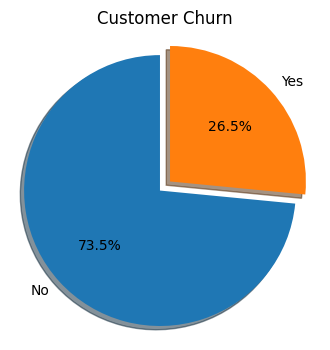

In [43]:
# Membuat pie chart
plt.figure(figsize=(4, 4))
plt.pie(total_churn, labels=total_churn.index, autopct='%1.1f%%',
        explode=(0, 0.1), shadow=True,startangle=90)
plt.axis('equal')
plt.title('Customer Churn')
plt.show()


* Total Customer yang churn cukup besar, yaitu 26,5%. Butuh analisis lebih dalam untuk mengetahui penyebab churn 26,5% tersebut.

2. Apakah kontrak yang lebih pendek mempengaruhi customer churn ?

In [44]:
kontrak_churn = pd.crosstab(df['Contract'],df['Churn Label'],normalize='index')
kontrak_churn

Churn Label,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


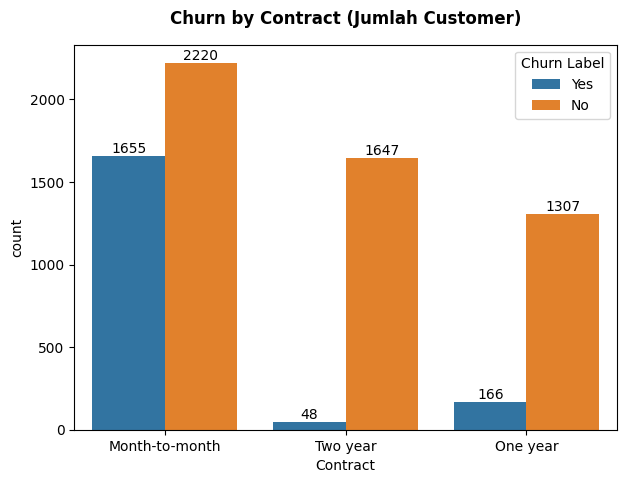

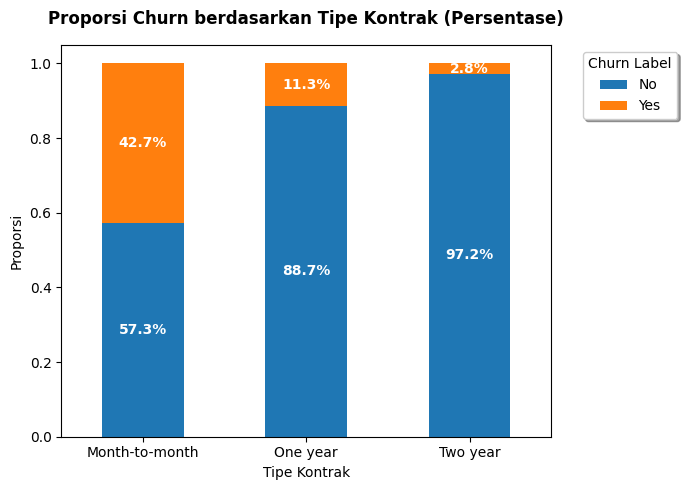

In [45]:
# 1. Menampilkan angka pada sns.countplot
plt.figure(figsize=(7,5))
ax1 = sns.countplot(data=df, x='Contract', hue='Churn Label')
plt.title('Churn by Contract (Jumlah Customer)', fontsize=12, fontweight='bold', pad=15)

# Menambahkan label angka di setiap batang
for container in ax1.containers:
    ax1.bar_label(container)

plt.show()

# 2. Menampilkan angka persentase pada Stacked Bar Chart dengan Legend yang Rapi
ax2 = kontrak_churn.plot(kind='bar', figsize=(7, 5), stacked=True, color=['#1f77b4', '#ff7f0e'])
plt.title('Proporsi Churn berdasarkan Tipe Kontrak (Persentase)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Proporsi')
plt.xlabel('Tipe Kontrak')
plt.xticks(rotation=0)

# Merapikan Legend (dipindahkan ke sebelah kanan luar diagram agar tidak menumpuk)
plt.legend(title='Churn Label', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True, shadow=True)

# Menambahkan label persentase di dalam batang
for container in ax2.containers:
    # Menampilkan label dengan format persentase (1 desimal, misal: 42.7%)
    ax2.bar_label(container, fmt=lambda x: f'{x*100:.1f}%' if x > 0 else '', label_type='center', fontweight='bold', color='white')

plt.tight_layout()
plt.show()

* Dari total customer yang ada, kebanyakan memiliki kontrak 'month-to-month'. Dan penyumbang churn terbanyak juga dari jenis kontrak 'month-to-month' sebesar 42,7% dari total customer dengan kontrak tersebut. perlu perhatian serius untuk customer dengan kontrak 'month-to-month'.
* Customer dengan kontrak 'one year' sudah lebih nyaman dan loyal, meskipun ada 11,3% customer yang churn dikelompok tersebut.
* Customer dengan kontrak 'two year' sudah sangat nyaman berlangganan dan sudah loyal.